# Text as data

A model needs numbers, but a customs decision is a description of goods in one of 23 languages. After this block you can split such texts into tokens, choose sensible preprocessing for a multilingual corpus, represent documents as word counts and TF-IDF vectors with n-grams, explain why the resulting matrix is stored as a sparse matrix, and compute simple text statistics that need no vocabulary.

This block starts the EBTI case study of Sessions 13–16: predict the four-digit customs heading of a product from its description. Block 2 sets up the task and the leaderboard; here we only look at the text.

## Teaching map

| Section | Minutes | What it delivers |
|---|---|---|
| 1 · Documents, tokens and vocabulary | 6 | corpus, document, token, type, vocabulary; `fit` learns the vocabulary |
| 2 · Preprocessing | 8 | lower-casing, stop words, stemming, lemmatisation, and why every rule needs a language |
| 3 · Bag-of-words computed by hand | 6 | the document-term matrix from three short descriptions |
| 4 · TF-IDF and n-grams | 10 | idf by hand, scikit-learn's variant, word and character n-grams |
| 5 · Sparse, high-dimensional matrices | 6 | CSR storage, sparsity, Zipf's law, `min_df` and `max_df` |
| 6 · Simple text statistics as features | 4 | length, digits, upper-case share; what they really measure |
| Worked example · vocabulary across languages | 5 | the practice task: vocabularies per language and the effect of preprocessing |

**Core path for the 45-minute lecture:** the numbered sections without the subsections marked *(depth: self-study or if time allows)*, plus the worked example. The depth subsections go further: tokenising with a dictionary vectoriser, cleaning text with regular expressions, stemmers compared, the parameters of `TfidfVectorizer`, character versus word-boundary n-grams, the hashing trick, and text statistics combined with TF-IDF in one pipeline. They are written for self-study after class.

```mermaid
flowchart LR
    A["Description<br/>of goods"] --> B["Normalise<br/>(lower-case)"]
    B --> C["Tokenise<br/>(words or characters)"]
    C --> D["Filter or reduce<br/>(stop words, stemming)"]
    D --> E["Vocabulary<br/>(fit on training data)"]
    E --> F["Count and weight<br/>(counts, TF-IDF)"]
    F --> G["Sparse document-term<br/>matrix"]
    G --> H["Model<br/>(Block 2)"]
```

In [1]:
# Run the code from the repository root, where the case-study paths start.
import os
from pathlib import Path

os.chdir(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "case-study").is_dir()))

## 1 · Documents, tokens and vocabulary

A **corpus** is a collection of texts, and each text in it is a **document**. In the case study one document is the description of goods of one customs decision.

To count anything we first cut a document into **tokens**, usually words. A **type** is a distinct token: "toy car made of plastic, plastic car" has seven tokens but only five types. The **vocabulary** is the list of types a model knows; each type gets one fixed column number, like the index at the back of a book that gives every word one entry.

A word that is not in the vocabulary has no column, so the model cannot see it. This is the **out-of-vocabulary** problem: a new product name, a typo or a word from a rare language is simply ignored.

Next we tokenise two short descriptions by hand. `str.lower()` lower-cases, `str.split()` cuts at white space, and a `set` keeps each type once.

In [2]:
docs = ["Toy car made of plastic.", "Car seat cover made of textile."]
tokens = [d.lower().replace(".", "").split() for d in docs]
print(tokens)
vocab = sorted(set(tokens[0]) | set(tokens[1]))
print(len(tokens[0]) + len(tokens[1]), "tokens,", len(vocab), "types:", vocab)

[['toy', 'car', 'made', 'of', 'plastic'], ['car', 'seat', 'cover', 'made', 'of', 'textile']]
11 tokens, 8 types: ['car', 'cover', 'made', 'of', 'plastic', 'seat', 'textile', 'toy']


scikit-learn does the same with `CountVectorizer`: `fit` learns the vocabulary, `transform` counts the vocabulary words in any text, and `vocabulary_` maps each word to its column.

**Predict before running:** the new text "Toy truck made of wood." has five words. How many of them get a count?

In [3]:
from sklearn.feature_extraction.text import CountVectorizer

cv = CountVectorizer().fit(docs)            # learn the vocabulary from the two documents
print(cv.vocabulary_)
print(cv.transform(["Toy truck made of wood."]).toarray())

{'toy': 7, 'car': 0, 'made': 2, 'of': 3, 'plastic': 4, 'seat': 5, 'cover': 1, 'textile': 6}
[[0 0 1 1 0 0 0 1]]


Only `made`, `of` and `toy` are counted; `truck` and `wood` are out of vocabulary and disappear without a warning.

Now the real corpus. `pd.read_parquet` reads the 50,000-decision sample; `.str.split().str.len()` counts the tokens of every description at once.

In [4]:
import pandas as pd

decisions = pd.read_parquet("case-study/data/train_sample.parquet")
texts = decisions["description"]
n_tokens = texts.str.split().str.len()
print(len(texts), "documents,", int(n_tokens.sum()), "tokens, median", n_tokens.median(), "tokens per description")
print(decisions["language"].nunique(), "languages; most frequent:",
      decisions["language"].value_counts(normalize=True).head(3).round(2).to_dict())

50000 documents, 4504393 tokens, median 82.0 tokens per description
23 languages; most frequent: {'de': 0.57, 'fr': 0.16, 'en': 0.05}


> **Note.** Fit the vocabulary on training data only. If `fit` also sees validation or test documents, information from them leaks into the model. Inside a scikit-learn `Pipeline` (Session 7) the vectoriser is refitted on each training fold automatically.

**In practice.** Search engines such as Elasticsearch pass every document and every query through the same *analyzer* (tokeniser plus normalisation), with one analyzer per language, so that query tokens and document tokens match. Customs administrations work on the same task as this course: tools that suggest HS codes from the free-text goods descriptions of declarations, so that officers check suggestions instead of searching the tariff.

### Tokens, frequency dictionaries and `DictVectorizer` (depth: self-study or if time allows)

*Adapted from [FeatureHasher and DictVectorizer Comparison](https://scikit-learn.org/stable/auto_examples/text/plot_hashing_vs_dict_vectorizer.html) (scikit-learn developers, BSD-3-Clause), on EBTI data.*

A token may be a word, part of a word or anything between spaces or symbols in a string. We can write our own tokeniser with a simple regular expression that matches Unicode word characters, `\w+`: this includes most characters that can be part of a word in any language, as well as digits and the underscore. A generator expression `(... for ... in ...)` yields the lower-cased tokens one by one.

In [5]:
import re


def tokenize(doc):
    # Extract lower-cased tokens from doc with a simple regex for word characters.
    return (tok.lower() for tok in re.findall(r"\w+", doc))


print(list(tokenize("Spielzeugauto aus Kunststoff, 30 cm lang; isn't it?")))

['spielzeugauto', 'aus', 'kunststoff', '30', 'cm', 'lang', 'isn', 't', 'it']


A second function counts how often each token occurs in a document and returns a frequency dictionary. `collections.defaultdict(int)` starts every new key at 0.

In [6]:
from collections import defaultdict


def token_freqs(doc):
    # Map each token of doc to its number of occurrences.
    freq = defaultdict(int)
    for tok in tokenize(doc):
        freq[tok] += 1
    return dict(freq)


print(token_freqs("Schuhe mit Oberteil aus Leder und Laufsohle aus Kunststoff"))

{'schuhe': 1, 'mit': 1, 'oberteil': 1, 'aus': 2, 'leder': 1, 'und': 1, 'laufsohle': 1, 'kunststoff': 1}


The repeated token `aus` is counted twice. Breaking a document into tokens and losing their order is the bag-of-words representation of section 3.

`DictVectorizer` turns a list of such dictionaries into a matrix: it learns one column per key it has seen. The mapping from token to column is stored in `vocabulary_`, an ordinary Python dictionary that grows with the corpus. Next we vectorise 10,000 descriptions this way.

In [7]:
from sklearn.feature_extraction import DictVectorizer

sample = texts.sample(10_000, random_state=0)
dv = DictVectorizer()
M = dv.fit_transform(token_freqs(d) for d in sample)
print(type(dv.vocabulary_).__name__, f"with {len(dv.vocabulary_):,} entries; matrix shape {M.shape}")
print("column of 'kunststoff':", dv.vocabulary_["kunststoff"])

dict with 85,235 entries; matrix shape (10000, 85235)
column of 'kunststoff': 40167


`CountVectorizer` does the same job in one class, with more options (token pattern, n-grams, `min_df`) and faster, because it compiles its regular expression once for the whole corpus. Its default pattern `(?u)\b\w\w+\b` also drops one-character tokens such as `s` in "isn't".

## 2 · Preprocessing: lower-casing, stop words, stemming and lemmatisation

Preprocessing maps different surface forms of a word to one form, so that counts are pooled and the vocabulary becomes smaller.

- **Lower-casing**: "Kunststoff" and "KUNSTSTOFF" become one word. Some decisions are written entirely in capitals, so this matters here.
- **Stop words** are frequent function words ("the", "and", "aus", "mit", "de"). Removing them saves columns, but scikit-learn ships only an **English** list.
- **Stemming** cuts word endings with fixed rules: "Spielzeuge" and "Spielzeugen" become `spielzeug`. A stem need not be a real word.
- **Lemmatisation** looks a word up in a dictionary, together with its part of speech, and returns its base form, the **lemma** ("mice" → "mouse", "better" as an adjective → "good"). It needs a trained model per language and is slower than stemming.

Every step also throws information away, and in a corpus with 23 languages every rule must exist 23 times. Think of a spell-checker: it is only useful if it knows the language you write in.

A special problem of German, Dutch and Swedish is **compounding**: "Kinderspielzeug", "Kunststoffspielzeug" and "Holzspielzeug" (children's, plastic and wooden toy) are three tokens that share no column with "Spielzeug". Stemming does not help, because the stem is the whole compound. Character n-grams (section 4) do.

| Step | Vocabulary | Information lost | Cost |
|---|---|---|---|
| lower-casing | smaller | little (German nouns are capitalised, but the word stays) | none |
| stop-word removal | slightly smaller | "ohne" (without), "nicht" (not), "pour" (for) can matter for a tariff | one list per language |
| stemming | smaller | distinct words may merge | one stemmer per language |
| lemmatisation | smaller | little | one trained model per language; slow |
| character n-grams (section 4) | much larger | none; replaces most of the above | many more features |

```mermaid
flowchart TD
    Q{"One language<br/>or many?"} -->|one| S{"Labelled data<br/>scarce?"}
    Q -->|many| C["Keep words as they are<br/>and add character n-grams<br/>(no per-language rules)"]
    S -->|no| K["Keep the defaults:<br/>lower-case only"]
    S -->|yes| L["Try stemming or<br/>lemmatisation"]
    C --> V["Compare on validation data"]
    K --> V
    L --> V
```

Next we tokenise a German description with scikit-learn's default token pattern. `re.findall(pattern, text)` returns all matches; `(?u)\b\w\w+\b` means "two or more letters or digits". Then we drop the words in `ENGLISH_STOP_WORDS`.

**Predict before running:** how many of the eleven German tokens does the English stop-word list remove?

In [8]:
import re

from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

text = "Kinderspielzeug aus Kunststoff, in Form eines Autos, mit Rädern aus Gummi"
words = re.findall(r"(?u)\b\w\w+\b", text.lower())
print(words)
print([w for w in words if w not in ENGLISH_STOP_WORDS])

['kinderspielzeug', 'aus', 'kunststoff', 'in', 'form', 'eines', 'autos', 'mit', 'rädern', 'aus', 'gummi']
['kinderspielzeug', 'aus', 'kunststoff', 'form', 'eines', 'autos', 'mit', 'rädern', 'aus', 'gummi']


Only `in` goes: the English list does not know German.

Next, stemming. `SnowballStemmer("german")` from NLTK applies the Snowball rules for one language; it is pure Python and needs no data download. `.stem(word)` returns the stem.

In [9]:
from nltk.stem.snowball import SnowballStemmer

german, french = SnowballStemmer("german"), SnowballStemmer("french")
print([german.stem(w) for w in ["Spielzeug", "Spielzeuge", "Spielzeugen", "Kunststoffen", "Rädern"]])
print([french.stem(w) for w in ["jouet", "jouets", "chaussure", "chaussures"]])

['spielzeug', 'spielzeug', 'spielzeug', 'kunststoff', 'rad']
['jouet', 'jouet', 'chaussur', 'chaussur']


Lemmatisation needs a dictionary. NLTK's `WordNetLemmatizer` (English only) uses the WordNet data, which is a separate download. The next cell runs only if that data is already on your machine; we do not download it in class.

In [10]:
import nltk

try:
    nltk.data.find("corpora/wordnet")
    from nltk.stem import WordNetLemmatizer

    lem = WordNetLemmatizer()
    print([lem.lemmatize(w) for w in ["mice", "feet", "studies"]], lem.lemmatize("better", pos="a"))
except LookupError:
    print("WordNet data not installed: see the expected output below (nltk.download('wordnet') installs it).")

WordNet data not installed: see the expected output below (nltk.download('wordnet') installs it).


Expected output with the WordNet data: `['mouse', 'foot', 'study'] good`. A stemmer cannot do this, because "mice" and "mouse" share no ending. For German, French and the other EBTI languages, lemmatisers come with libraries such as spaCy or Stanza (not part of the course environment).

How much do these choices change the vocabulary of the case study? `CountVectorizer(lowercase=False)` keeps capitals and `stop_words="english"` removes the English list. We use a 10,000-decision subsample to keep the cell fast; `.sample(n, random_state=0)` draws it reproducibly.

In [11]:
sample = texts.sample(10_000, random_state=0)
for name, vec in [("default (lower-case)", CountVectorizer()),
                  ("no lower-casing", CountVectorizer(lowercase=False)),
                  ("English stop words removed", CountVectorizer(stop_words="english"))]:
    print(f"{name:28s} {len(vec.fit(sample).vocabulary_):>7,} words")

default (lower-case)          85,164 words


no lower-casing               93,588 words


English stop words removed    84,970 words


Lower-casing saves several thousand columns; the English stop-word list removes only a few hundred, because most of the corpus is not English.

> **Note.** `stop_words="english"` also removes negations such as "not" and "without". "Shoes without laces" and "shoes with laces" can belong to different tariff codes. If you remove stop words at all, use your own list per language and check it.

**In practice.** Elasticsearch offers stemmer, stop-word and *decompounder* filters for German, Dutch and the Scandinavian languages, so that a query for "Spielzeug" also finds "Kinderspielzeug". Libraries such as spaCy and Stanza provide tokenisers and lemmatisers for dozens of languages, which is why multilingual projects often start with them rather than with hand-written rules.

### Cleaning text with string methods and regular expressions (depth: self-study or if time allows)

*Adapted from [Regular Expressions](https://github.com/DS-100/course-notes/blob/main/content/regex/regex.ipynb) (Data 100 course notes, UC Berkeley, BSD-3-Clause); rewritten from Polars to pandas and applied to EBTI descriptions.*

There are two main reasons for working with text before any model sees it:

1. **Canonicalisation**: convert data that has multiple formats into one standard form, for example to find duplicates or to join tables whose labels are spelled differently.
2. **Extraction**: pull a piece of information out of the text into a new feature, for example a fibre share or a date.

Python's string methods work on one string; pandas offers the same operations **vectorised** for a whole column through the `.str` accessor.

| Operation | Python (one string) | pandas (`Series`) |
|:---|:---|:---|
| transformation | `s.lower()`, `s.upper()` | `ser.str.lower()`, `ser.str.upper()` |
| replacement and deletion | `s.replace(...)`, `re.sub(...)` | `ser.str.replace(..., regex=...)` |
| split | `s.split(...)`, `re.split(...)` | `ser.str.split(...)` |
| substring | `s[1:4]` | `ser.str[1:4]` |
| membership | `"ab" in s`, `re.search(...)` | `ser.str.contains(...)` |
| extraction | `re.findall(...)` | `ser.str.findall(...)`, `ser.str.extract(...)`, `ser.str.extractall(...)` |
| length | `len(s)` | `ser.str.len()` |
| strip | `s.strip()` | `ser.str.strip()` |

**Canonicalisation on the case study.** Two descriptions that differ only in capitals, line breaks or spaces are the same text for a person. Next we write a function that lower-cases, collapses every run of white space into one space and strips the ends, and count how many distinct descriptions remain. `ser.str.replace(r"\s+", " ", regex=True)` replaces a regular expression in every row.

In [12]:
def canonicalise(ser):
    return ser.str.lower().str.replace(r"\s+", " ", regex=True).str.strip()


print(f"distinct raw descriptions:          {texts.nunique():,}")
print(f"distinct after canonicalisation:    {canonicalise(texts).nunique():,}")

distinct raw descriptions:          49,411


distinct after canonicalisation:    49,345


A few more descriptions turn out to be duplicates once formatting is ignored. This matters in Block 2: duplicates on both sides of a train-validation split make a model look better than it is.

**Regular expressions.** A *regular expression* (regex) is a sequence of characters that specifies a search pattern. It is a small language of its own, available in Python through the `re` module. Four basic operations build every pattern:

| Operation | Order | Example | Matches | Does not match |
| :--- | :--- | :--- | :--- | :--- |
| or: `\|` | 4 | `AA\|BAAB` | `AA`, `BAAB` | every other string |
| concatenation | 3 | `AABAAB` | `AABAAB` | every other string |
| closure: `*` (zero or more) | 2 | `AB*A` | `AA`, `ABBBBBBA` | `AB`, `ABABA` |
| group: `()` | 1 | `A(A\|B)AAB`, `(AB)*A` | `AAAAB`, `ABAAB`; `A`, `ABABABABA` | every other string; `AA`, `ABBA` |

These **metacharacters** act on their neighbours rather than standing for themselves; `()` binds first, then `*`, then concatenation, then `|`. So `AB*` means "A, then zero or more B", while `(AB)*` means "zero or more copies of AB". Useful shorthands: `\d` a digit, `\w` a word character, `\s` white space, `[^>]` any character except `>`, `{2}` exactly two times, `+` one or more, `?` optional. Always write patterns as raw strings, `r"..."`, so that Python does not interpret the backslashes.

Next we use `re.sub(pattern, repl, text)` to delete the placeholder `<CODE>` (numbers that repeated the decision's own code were replaced by it) and `re.findall` to list all matches of a pattern.

In [13]:
example = texts[texts.str.contains("<CODE>", regex=False)].iloc[0]
pos = example.find("<CODE>")
print(" ".join(example[pos - 60:pos + 30].split()))
print(" ".join(re.sub(r"<[^>]+>", "", example)[pos - 60:pos + 24].split()))   # '<', anything but '>', '>'
print(re.findall(r"\d+", example)[:10])            # all runs of digits

enoemd noch elders onder begrepen zoals bedoeld bij GS-post <CODE> van de gecombineerde no
enoemd noch elders onder begrepen zoals bedoeld bij GS-post van de gecombineerde no
['1', '28', '2836', '25']


**Capture groups.** Parentheses also *capture*: `re.findall` with groups returns one tuple per match, and pandas `ser.str.extractall` returns one row per match with one column per group. Next we extract the fibre composition of textiles ("95 % cotton") as a number and the word that follows. `(?:...)` is a group that does not capture; `[.,]` matches a point or a comma.

In [14]:
fibre = r"(\d+(?:[.,]\d+)?)\s?%\s?(\w+)"
print(re.findall(fibre, "T-shirt aus 95 % Baumwolle und 5 % Elastan"))
found = texts.str.extractall(fibre)
print(f"{found.index.get_level_values(0).nunique():,} descriptions contain a share in per cent")
print(found[1].str.lower().value_counts().head(8).to_dict())

[('95', 'Baumwolle'), ('5', 'Elastan')]


4,199 descriptions contain a share in per cent
{'polyester': 1415, 'baumwolle': 602, 'de': 316, 'elasthan': 249, 'poliéster': 213, 'vol': 165, 'polyamid': 165, 'coton': 153}


Check what an extraction rule really finds. The most frequent "fibres" include `de` (French writes "100 % de coton") and `vol` ("% vol" is the alcohol strength of a drink): a pattern that looks right on one example needs to be checked on the whole column.

**Limits of regular expressions.** Writing a regex is like writing a small program: easier to write than to read, and hard to debug. Regular expressions are the wrong tool for hierarchical formats (use `json.load` for JSON and an HTML parser for HTML) and for counting matched pairs. Use them for clear, well-defined patterns such as numbers, units or codes; leave fuzzier text tasks to models.

### Stemmers compared (depth: self-study or if time allows)

A stemmer can make two kinds of mistakes. **Over-stemming** merges words with different meanings into one stem; **under-stemming** leaves forms of the same word apart. NLTK's `PorterStemmer` (Porter, 1980) and `LancasterStemmer` are English rule sets; `LancasterStemmer` cuts more aggressively. Next we compare them with the English Snowball stemmer on a few words.

In [15]:
from nltk.stem import LancasterStemmer, PorterStemmer

stemmers = {"porter": PorterStemmer(), "snowball": SnowballStemmer("english"), "lancaster": LancasterStemmer()}
words_en = ["connection", "connected", "connecting", "experiment", "experience", "running", "ran", "wolves"]
pd.DataFrame({name: [s.stem(w) for w in words_en] for name, s in stemmers.items()}, index=words_en)

,porter,snowball,lancaster
connection,connect,connect,connect
connected,connect,connect,connect
connecting,connect,connect,connect
experiment,experi,experi,expery
experience,experi,experi,expery
running,run,run,run
ran,ran,ran,ran
wolves,wolv,wolv,wolv


Read the table for both errors: which different words end up with the same stem, and which forms of one word ("running", "ran") stay apart because the change is not at the end of the word.

Which EBTI languages have a Snowball stemmer at all? `SnowballStemmer.languages` lists them; next we map the EBTI language codes to these names and count the decisions that a per-language stemmer could cover.

In [16]:
code_to_name = {"de": "german", "fr": "french", "en": "english", "nl": "dutch", "es": "spanish",
                "sv": "swedish", "it": "italian", "da": "danish", "hu": "hungarian", "ro": "romanian",
                "fi": "finnish", "pt": "portuguese"}
covered = decisions["language"].map(lambda c: code_to_name.get(c) in SnowballStemmer.languages)
print(sorted(set(decisions["language"]) - set(code_to_name)), "have no Snowball stemmer")
print(f"share of decisions with a stemmer for their language: {covered.mean():.1%}")

['bg', 'cs', 'el', 'et', 'hr', 'lt', 'lv', 'mt', 'pl', 'sk', 'sl'] have no Snowball stemmer
share of decisions with a stemmer for their language: 91.5%


Eleven of the 23 languages (Bulgarian, Czech, Greek, Estonian, Croatian, Lithuanian, Latvian, Maltese, Polish, Slovak and Slovenian) have no Snowball stemmer in NLTK, although the frequent languages are covered. A stemming pipeline for this corpus would need a language detector, a dispatch table and a fallback, and every part can fail. This is one more argument for character n-grams on multilingual data.

> 📖 **Read more:** [extras/01-data100-text-wrangling-regex.ipynb](extras/01-data100-text-wrangling-regex.ipynb) (Data 100, UC Berkeley): the original notes with more regex examples (log files, HTML tags, capture groups) and exercises with answers, in Polars.

## 3 · Bag-of-words computed by hand

The **bag-of-words** representation describes a document only by how often each vocabulary word occurs in it. The order of the words is thrown away, as if the words were shaken in a bag. Stacking the count vectors of all documents gives the **document-term matrix** (DTM): one row per document, one column per word.

By hand, for three descriptions:

- d1 = "toy car, plastic car"
- d2 = "plastic box with lid"
- d3 = "toy box made of wood"

The vocabulary in alphabetical order is `box, car, lid, made, of, plastic, toy, with, wood`, and the counts are

| | box | car | lid | made | of | plastic | toy | with | wood |
|---|---|---|---|---|---|---|---|---|---|
| d1 | 0 | 2 | 0 | 0 | 0 | 1 | 1 | 0 | 0 |
| d2 | 1 | 0 | 1 | 0 | 0 | 1 | 0 | 1 | 0 |
| d3 | 1 | 0 | 0 | 1 | 1 | 0 | 1 | 0 | 1 |

A row sum is the length of a document in tokens; a column sum is how often a word occurs in the corpus. Most cells are zero, even here.

Next we let scikit-learn build the same table. `fit_transform` learns the vocabulary and counts in one step, `get_feature_names_out()` lists the columns, and `.toarray()` turns the small sparse result into an ordinary array for printing. `.sum(axis=1)` sums each row.

In [17]:
mini = ["toy car, plastic car", "plastic box with lid", "toy box made of wood"]
cv = CountVectorizer()
X = cv.fit_transform(mini)
print(cv.get_feature_names_out())
print(X.toarray())
print("row sums:", X.sum(axis=1).A1)

['box' 'car' 'lid' 'made' 'of' 'plastic' 'toy' 'with' 'wood']
[[0 2 0 0 0 1 1 0 0]
 [1 0 1 0 0 1 0 1 0]
 [1 0 0 1 1 0 1 0 1]]
row sums: [4 4 5]


The figure shows the same idea for five short descriptions in three languages. An English and a German description of the same toy share no column, so to a bag-of-words model they look unrelated. A classifier can still learn both, but only from labelled examples in each language.

![Heatmap of a document-term matrix with five short descriptions in English, German and French as rows and the vocabulary words as columns; most cells are zero and the languages share almost no columns](../figures/dtm_sketch.png)

A bag-of-words vector is a point in a space with one axis per word. Two documents are similar if they use the same words in similar proportions.

Counts are not the only choice. `CountVectorizer(binary=True)` records only whether a word occurs (1) or not (0), which often works as well for short texts where words rarely repeat.

In [18]:
print(CountVectorizer(binary=True).fit_transform(mini).toarray()[0], "<- d1 with binary=True: 'car' is 1, not 2")

[0 1 0 0 0 1 1 0 0] <- d1 with binary=True: 'car' is 1, not 2


> **Note.** "Bag-of-words" does not mean "single words only". The columns can also be pairs of words or character sequences (section 4). What makes it a bag is that the position of each unit in the document is ignored.

**In practice.** Spam filters have classified e-mail from word counts since the late 1990s; Paul Graham's essay *A Plan for Spam* (2002) popularised naive Bayes on token counts for this task. Mosteller and Wallace (1964) attributed the disputed *Federalist Papers* to James Madison by comparing how often the candidate authors used common words such as "upon", one of the earliest statistical studies that treated text as counts.

## 4 · TF-IDF and n-grams

### TF-IDF

Raw counts are dominated by words such as "mit" or "de" that occur everywhere and say nothing about the goods. **TF-IDF** weights each count by how rare the word is in the corpus:

- **term frequency** tf(t, d): how often term t occurs in document d;
- **document frequency** df(t): in how many of the N documents t occurs;
- **inverse document frequency** idf(t) = ln(N / df(t)): large for rare words, zero for a word in every document.

The weight is tf × idf: high if a word is frequent in this document and rare elsewhere. Like a highlighter, it marks what makes this description different from the others.

By hand, with N = 3: d1 = "plastic toy plastic box", d2 = "plastic bag", d3 = "wooden toy".

| Term in d1 | tf | df | idf = ln(3 / df) | tf × idf |
|---|---|---|---|---|
| plastic | 2 | 2 | 0.405 | 0.811 |
| toy | 1 | 2 | 0.405 | 0.405 |
| box | 1 | 1 | 1.099 | 1.099 |

"box" occurs only once in d1 but gets the highest weight, because no other document uses it.

scikit-learn's `TfidfVectorizer` changes the textbook formula in two ways (and offers a third):

1. **smoothed idf** = ln((1 + N) / (1 + df)) + 1, which avoids division by zero and never gives a word weight zero;
2. **L2 normalisation**: each row is divided by its length, so long German and short French descriptions become comparable;
3. optionally `sublinear_tf=True`, which replaces tf by 1 + ln(tf), so the tenth "Kunststoff" adds less than the second.

Next we compute scikit-learn's version for d1 by hand with NumPy. `np.log` is the natural logarithm and `np.linalg.norm` the Euclidean length of a vector.

In [19]:
import numpy as np

tf = {"plastic": 2, "toy": 1, "box": 1}
df = {"plastic": 2, "toy": 2, "box": 1}
idf = {w: np.log((1 + 3) / (1 + df[w])) + 1 for w in tf}
weights = np.array([tf[w] * idf[w] for w in tf])
print({w: round(float(v), 3) for w, v in idf.items()})
print({w: round(float(v), 3) for w, v in zip(tf, weights / np.linalg.norm(weights))})

{'plastic': 1.288, 'toy': 1.288, 'box': 1.693}
{'plastic': 0.771, 'toy': 0.386, 'box': 0.507}


**Predict before running:** which word of d1 will `TfidfVectorizer` weight highest, and how long is each row vector?

In [20]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer()
T = tfidf.fit_transform(["plastic toy plastic box", "plastic bag", "wooden toy"])
print(tfidf.get_feature_names_out())
print(T.toarray().round(3))
print("row lengths:", np.linalg.norm(T.toarray(), axis=1))

['bag' 'box' 'plastic' 'toy' 'wooden']
[[0.    0.507 0.771 0.386 0.   ]
 [0.796 0.    0.605 0.    0.   ]
 [0.    0.    0.    0.605 0.796]]
row lengths: [1. 1. 1.]


With smoothing and normalisation `plastic` wins in d1, while the textbook formula preferred `box`: the variant matters when you name "the most important word".

On the case study, `idf_` holds the idf of every vocabulary word. `min_df=3` keeps only words that occur in at least three descriptions.

In [21]:
vec = TfidfVectorizer(min_df=3).fit(texts)
idf_s = pd.Series(vec.idf_, index=vec.get_feature_names_out()).sort_values()
print("lowest idf: ", idf_s.index[:8].tolist())
print("highest idf:", idf_s.index[-5:].tolist(), round(idf_s.iloc[-1], 2))

lowest idf:  ['in', 'mit', 'aus', 'und', 'der', 'als', 'einem', 'von']
highest idf: ['t3', 'gęstość', 'ecksäulen', 'passagierbereich', 'blaubeere'] 10.43


The lowest idf values belong to German function words, because German is the most frequent language: TF-IDF down-weights them without any stop-word list.

**In practice.** TF-IDF ranking was the core of classic search engines. Apache Lucene, on which Elasticsearch and Solr are built, used a TF-IDF similarity by default until version 6 (2016), when it switched to BM25, a refinement of the same idea that Session 15 uses for retrieval.

### `TfidfVectorizer` = `CountVectorizer` + `TfidfTransformer`, and its parameters (depth: self-study or if time allows)

*Adapted from [FeatureHasher and DictVectorizer Comparison](https://scikit-learn.org/stable/auto_examples/text/plot_hashing_vs_dict_vectorizer.html) (scikit-learn developers, BSD-3-Clause), on EBTI data.*

In a large corpus some words appear very often ("the", "a", "is" in English; "mit", "aus", "und" here) and carry no information about the content. Fed directly to a classifier, those frequent terms would shadow the rarer and more informative ones. `TfidfTransformer` re-weights a count matrix into TF-IDF values; `TfidfVectorizer` is `CountVectorizer` followed by `TfidfTransformer` in one class. Next we check that the two routes give the same matrix: `abs(A - B).max()` is the largest difference between two sparse matrices.

In [22]:
from sklearn.feature_extraction.text import TfidfTransformer

A = TfidfVectorizer().fit_transform(sample)
B = TfidfTransformer().fit_transform(CountVectorizer().fit_transform(sample))
print("largest difference:", abs(A - B).max())

largest difference: 3.3306690738754696e-16


The two-step route is useful when you want the counts and the weights separately, or want to put TF-IDF weighting after a `HashingVectorizer` (section 5).

The parameters you will use most:

| Parameter | Default | Effect |
|---|---|---|
| `lowercase` | `True` | lower-case before tokenising |
| `token_pattern` | `(?u)\b\w\w+\b` | what counts as a token (ignored if `analyzer` is not `"word"`) |
| `analyzer` | `"word"` | `"char"` or `"char_wb"` for character n-grams, or your own function |
| `ngram_range` | `(1, 1)` | smallest and largest n |
| `stop_words` | `None` | `"english"` or your own list |
| `min_df`, `max_df` | `1`, `1.0` | drop rare and ubiquitous terms (a count or a share of documents) |
| `max_features` | `None` | keep only the most frequent terms |
| `binary` | `False` | presence instead of counts |
| `use_idf`, `smooth_idf` | `True`, `True` | switch idf off, or use the textbook ln(N / df) + 1 |
| `sublinear_tf` | `False` | replace tf by 1 + ln(tf) |
| `norm` | `"l2"` | row normalisation (`"l1"` or `None` possible) |

Next we see `sublinear_tf` at work on a description that repeats one word four times. `T[0, j]` reads one cell of a sparse matrix and `vocabulary_[word]` gives the column `j`.

In [23]:
doc = ["Kunststoff Kunststoff Kunststoff Kunststoff Spielzeug", "Spielzeug aus Holz"]
for sub in [False, True]:
    v = TfidfVectorizer(sublinear_tf=sub)
    T2 = v.fit_transform(doc)
    print(f"sublinear_tf={sub}: kunststoff {T2[0, v.vocabulary_['kunststoff']]:.3f}, "
          f"spielzeug {T2[0, v.vocabulary_['spielzeug']]:.3f}")

sublinear_tf=False: kunststoff 0.985, spielzeug 0.175
sublinear_tf=True: kunststoff 0.958, spielzeug 0.286


With `sublinear_tf=True` the repeated word still leads, but the weight of the other word rises clearly: four repetitions no longer count four times.

### n-grams

An **n-gram** is a sequence of n consecutive tokens: unigrams are single words, **bigrams** pairs of words. `ngram_range=(1, 2)` puts both into the vocabulary.

Footwear shows why this can matter: heading 6403 covers shoes with leather uppers, 6404 shoes with textile uppers. "leather upper, textile sole" and "textile upper, leather sole" contain the same four words; only bigrams tell them apart.

**Predict before running:** are the two unigram vectors identical?

In [24]:
pair = ["leather upper, textile sole", "textile upper, leather sole"]
for rng in [(1, 1), (1, 2)]:
    cv = CountVectorizer(ngram_range=rng).fit(pair)
    print(rng, cv.get_feature_names_out())
    print(cv.transform(pair).toarray())

(1, 1) ['leather' 'sole' 'textile' 'upper']
[[1 1 1 1]
 [1 1 1 1]]
(1, 2) ['leather' 'leather sole' 'leather upper' 'sole' 'textile' 'textile sole'
 'textile upper' 'upper' 'upper leather' 'upper textile']
[[1 0 1 1 1 1 0 1 0 1]
 [1 1 0 1 1 0 1 1 1 0]]


The price is size: the number of distinct bigrams grows much faster than the number of words. Next we count the vocabulary for three n-gram ranges on the 10,000-decision subsample; `len(vectorizer.vocabulary_)` is the number of columns.

In [25]:
for rng in [(1, 1), (1, 2), (1, 3)]:
    v = TfidfVectorizer(ngram_range=rng, min_df=3).fit(sample)
    print(rng, f"{len(v.vocabulary_):,} columns")

(1, 1) 21,163 columns


(1, 2) 57,790 columns


(1, 3) 90,741 columns


**Character n-grams** use sequences of letters instead of words. With `analyzer="char_wb"` scikit-learn builds them inside word boundaries, padded with a space. They survive typos and inflections, and they let a German compound share columns with its parts. `build_analyzer()` returns the function that turns one text into its list of n-grams.

In [26]:
grams = CountVectorizer(analyzer="char_wb", ngram_range=(4, 4)).build_analyzer()
print(grams("Flasche"))
print(sorted(set(grams("Kunststoffflasche")) & set(grams("Flasche"))))

[' fla', 'flas', 'lasc', 'asch', 'sche', 'che ']
['asch', 'che ', 'flas', 'lasc', 'sche']


"Kunststoffflasche" (plastic bottle) is one word token that shares nothing with "Flasche" (bottle), but it shares character 4-grams. The cost is many more columns per document; Block 2 measures whether it pays off on the case study.

> **Note.** Combine n-grams with `min_df` or `max_features`, and check `len(vectorizer.vocabulary_)` before fitting a model.

**In practice.** Language identification uses character n-grams; Cavnar and Trenkle (1994) described the classic n-gram frequency method that many language detectors still follow. The fastText classifier (Joulin et al., 2017) represents words by their character n-grams, so that it handles morphologically rich languages and words it has never seen.

### `char` versus `char_wb`, and n-grams across word boundaries (depth: self-study or if time allows)

`analyzer="char"` slides a window over the whole text, spaces included, so its n-grams can span two words ("z a" from "Holz aus"). `analyzer="char_wb"` first splits into words and pads each word with one space on both sides, so every n-gram stays inside a word. Next we compare the 3-grams of a short phrase.

In [27]:
for analyzer in ["char", "char_wb"]:
    g = CountVectorizer(analyzer=analyzer, ngram_range=(3, 3)).build_analyzer()("Holz aus")
    print(f"{analyzer:8s} {len(g):2d} n-grams: {g}")

char      6 n-grams: ['hol', 'olz', 'lz ', 'z a', ' au', 'aus']
char_wb   7 n-grams: [' ho', 'hol', 'olz', 'lz ', ' au', 'aus', 'us ']


`char` keeps information about which words follow each other, at the cost of more and noisier columns; `char_wb` is the usual choice for compounds and inflections. Word n-grams have the same trade-off one level up: bigrams keep local order but multiply the vocabulary, as the count above showed.

## 5 · Sparse, high-dimensional matrices

The document-term matrix of a real corpus is **high-dimensional** (one column per word, hundreds of thousands with 23 languages) and **sparse** (almost every cell is zero, because one description uses a few dozen words). Storing all those zeros would be like a phone book that lists every possible number, including the ones nobody has.

A **sparse matrix** stores only the non-zero cells. The CSR format (compressed sparse row) that scikit-learn uses keeps three arrays:

- `data`: the non-zero values, row by row;
- `indices`: the column of each value;
- `indptr`: where each row starts in `data` (one entry more than there are rows).

Next we print the three arrays of the small matrix `X` from section 3. Row 0 is `data[indptr[0]:indptr[1]]` in the columns `indices[indptr[0]:indptr[1]]`.

In [28]:
X = CountVectorizer().fit_transform(mini)
print("data   ", X.data)
print("indices", X.indices)
print("indptr ", X.indptr)

data    [1 2 1 1 1 1 1 1 1 1 1 1]
indices [6 1 5 5 0 7 2 6 0 3 4 8]
indptr  [ 0  3  7 12]


Now the whole sample. `D.shape` gives documents × words, `D.nnz` the number of stored values, and the `.nbytes` of the three arrays the memory used.

In [29]:
cv = CountVectorizer()
D = cv.fit_transform(texts)
print("shape:", D.shape)
print(f"share of non-zero cells: {D.nnz / (D.shape[0] * D.shape[1]):.5f}")
sparse_mb = (D.data.nbytes + D.indices.nbytes + D.indptr.nbytes) / 1e6
print(f"{sparse_mb:.1f} MB sparse, {D.shape[0] * D.shape[1] * 8 / 1e9:.1f} GB if stored dense")

shape: (50000, 213583)
share of non-zero cells: 0.00029
37.4 MB sparse, 85.4 GB if stored dense


**Zipf's law** describes word frequencies in almost every language: a few words are extremely frequent and most words are rare. Next we sum each column with `D.sum(axis=0)` and plot frequency against rank on log–log axes with `ax.loglog`; Zipf's law shows up as a roughly straight line.

most frequent: ['mit', 'aus', 'und', 'der', 'in', 'de', 'einem', 'die']
share of words that occur only once: 0.5


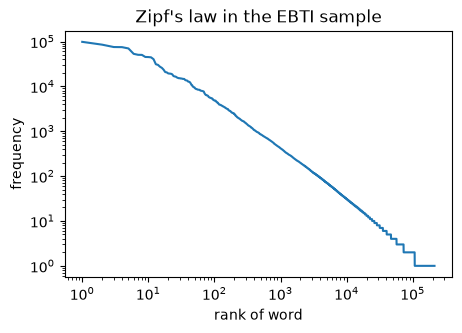

In [30]:
import matplotlib.pyplot as plt

counts = pd.Series(D.sum(axis=0).A1, index=cv.get_feature_names_out()).sort_values(ascending=False)
print("most frequent:", counts.index[:8].tolist())
print("share of words that occur only once:", round((counts == 1).mean(), 2))
fig, ax = plt.subplots(figsize=(5, 3.2))
ax.loglog(np.arange(1, len(counts) + 1), counts.to_numpy())
ax.set(xlabel="rank of word", ylabel="frequency", title="Zipf's law in the EBTI sample")
plt.show()

`min_df` drops words that occur in fewer than k documents and `max_df` drops words that occur in more than a given share of documents. Together they cut both tails of the Zipf curve.

In [31]:
small = CountVectorizer(min_df=5, max_df=0.5).fit(texts)
print(f"{len(small.vocabulary_):,} of {D.shape[1]:,} words remain")

42,871 of 213,583 words remain


Sparsity decides which models are practical. Linear models (Block 2) work directly on sparse input; methods that need dense input, such as standard PCA or most distance-based methods on raw counts, become slow or run out of memory.

> **Note.** Never call `.toarray()` on a full document-term matrix. Look at a few rows (`D[:5].toarray()`) or use sparse-aware functions such as `D.sum(axis=0)` and `D.nnz`.

> **Note.** `StandardScaler` subtracts the column means and would turn every zero into a non-zero number, destroying sparsity. For sparse text features use `StandardScaler(with_mean=False)` or `MaxAbsScaler`, or rely on the row normalisation of TF-IDF.

**In practice.** Document-term matrices are the input to classic topic models such as latent Dirichlet allocation (Blei, Ng and Jordan, 2003). Zipf's law (Zipf, 1949) appears in almost every language corpus and is the reason why vocabularies keep growing as more text is added; with several languages they grow faster still.

### The hashing trick: `FeatureHasher` and `HashingVectorizer` (depth: self-study or if time allows)

*Adapted from [FeatureHasher and DictVectorizer Comparison](https://scikit-learn.org/stable/auto_examples/text/plot_hashing_vs_dict_vectorizer.html) (scikit-learn developers, BSD-3-Clause), on EBTI data.*

A vocabulary is a dictionary that takes up memory and grows with the training set. **Feature hashing** avoids it: a hash function `h` maps each token directly to one of a fixed number of columns, and the count is added there. A hash function turns any string into a number; the same string always gives the same number. When the number of columns is too small, distinct tokens land in the same column (**hash collisions**), and it is impossible to tell from a column which token produced it. So the best estimate of the number of distinct tokens is the number of columns that are non-zero somewhere. Next we write that helper; `X.nonzero()` returns the row and column indices of all stored values.

In [32]:
def n_nonzero_columns(X):
    # Number of columns with at least one non-zero value in a sparse matrix.
    return len(np.unique(X.nonzero()[1]))

The default size of `FeatureHasher` is 2\*\*20 columns. We use 2\*\*18 to provoke collisions, then 2\*\*22, on the frequency dictionaries of the 10,000-decision subsample (`token_freqs` from section 1), and compare with the number of distinct tokens that `DictVectorizer` found. `time()` measures the duration.

In [33]:
from time import time

from sklearn.feature_extraction import FeatureHasher

print(f"DictVectorizer found {len(dv.vocabulary_):,} distinct tokens")
for n_features in [2**18, 2**22]:
    t0 = time()
    Xh = FeatureHasher(n_features=n_features).transform(token_freqs(d) for d in sample)
    print(f"FeatureHasher 2**{int(np.log2(n_features))}: {n_nonzero_columns(Xh):,} active columns "
          f"in {time() - t0:.2f} s")

DictVectorizer found 85,235 distinct tokens


FeatureHasher 2**18: 72,636 active columns in 0.26 s


FeatureHasher 2**22: 84,344 active columns in 0.27 s


With 2\*\*18 columns some tokens collide; with 2\*\*22 the number of active columns gets close to the true number of tokens. A larger space hardly changes the speed, but a model trained on it has more coefficients to store, even if most of them are never used.

`HashingVectorizer` combines the hashing trick with the tokenisation of `CountVectorizer`. It is **stateless**: `fit` learns nothing, so it can process data in batches or in a stream, and new product names never fall out of a vocabulary. It cannot compute idf on its own; put a `TfidfTransformer` after it if you need weights. Next we measure the speed of four vectorisers in MB of text per second and plot them with `ax.barh`.

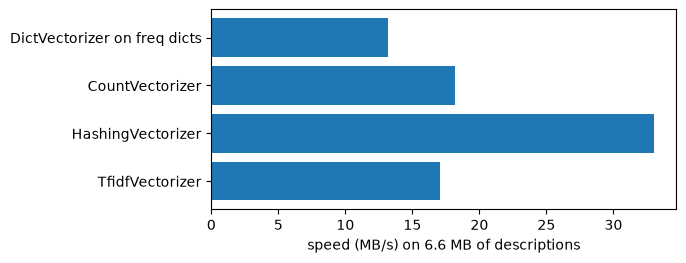

In [34]:
from sklearn.feature_extraction.text import HashingVectorizer

data_size_mb = sum(len(s.encode("utf-8")) for s in sample) / 1e6
speeds = {}
for name, fit in [("DictVectorizer on freq dicts", lambda: DictVectorizer().fit_transform(token_freqs(d) for d in sample)),
                  ("CountVectorizer", lambda: CountVectorizer().fit_transform(sample)),
                  ("HashingVectorizer", lambda: HashingVectorizer(n_features=2**18).fit_transform(sample)),
                  ("TfidfVectorizer", lambda: TfidfVectorizer().fit_transform(sample))]:
    t0 = time()
    fit()
    speeds[name] = data_size_mb / (time() - t0)
fig, ax = plt.subplots(figsize=(6, 2.6))
ax.barh(list(speeds), list(speeds.values()))
ax.invert_yaxis()
ax.set_xlabel(f"speed (MB/s) on {data_size_mb:.1f} MB of descriptions")
plt.show()

The exact speeds depend on your laptop. As a rule, `CountVectorizer` and `HashingVectorizer` beat the dictionary route because they compile their regular expression once for the whole corpus instead of once per document; `HashingVectorizer` is fastest because it keeps no vocabulary; `TfidfVectorizer` is slightly slower than `CountVectorizer` because of the extra weighting step. The price of hashing is that the transformation cannot be inverted: you cannot read the top words of a model trained on hashed features.

**In practice.** Weinberger et al. (2009) described the hashing trick for spam filtering with many users at Yahoo: one model per user would need a huge vocabulary, hashed features keep the memory fixed.

> 📖 **Read more:** [extras/02-sklearn-hashing-vs-dict-vectorizer.ipynb](extras/02-sklearn-hashing-vs-dict-vectorizer.ipynb) (scikit-learn gallery): the original comparison on 20 Newsgroups posts, with `FeatureHasher` on raw tokens (`input_type="string"`) as a further variant.

## 6 · Simple text statistics as features

A **text statistic** is a number computed from a string without any vocabulary: the length, the number of digits, the share of capital letters, or whether a pattern such as "%" occurs. It is computed from the row alone, so it needs no `fit` and cannot leak information from other rows.

By hand: "T-shirt, knitted, 95 % cotton, 5 % elastane, for women" has 54 characters, 3 digits, 1 capital among 35 letters and a per-cent sign.

Next we write a function that computes four statistics for a whole column. `Series.map(func)` applies a function to every string; `str.isdigit()`, `str.isupper()` and `str.isalpha()` test single characters.

In [35]:
def text_stats(text):
    # Four statistics per description; nothing is learned, so nothing needs fitting.
    t = text.fillna("")
    letters = t.map(lambda s: sum(ch.isalpha() for ch in s)).clip(lower=1)
    return pd.DataFrame({
        "n_chars": t.str.len(),
        "n_digits": t.map(lambda s: sum(ch.isdigit() for ch in s)),
        "upper_share": t.map(lambda s: sum(ch.isupper() for ch in s)) / letters,
        "has_percent": t.str.contains("%", regex=False).astype(int),
    }, index=text.index)


print(text_stats(pd.Series(["T-shirt, knitted, 95 % cotton, 5 % elastane, for women"])).round(2))

   n_chars  n_digits  upper_share  has_percent
0       54         3         0.03            1


**Predict before running:** German descriptions are long. Is the median length of a German description closer to that of a French one, or more than twice as long?

In [36]:
stats = text_stats(texts)
print(stats.groupby(decisions["language"])[["n_chars", "n_digits"]].median().loc[["de", "fr", "en"]])
mostly_caps = stats["upper_share"] > 0.8
print(mostly_caps.groupby(decisions["issuing_country"]).mean().nlargest(3).round(2).to_dict())
textile = decisions["chapter"].astype(int).between(50, 63)
print("per-cent sign, textiles vs other:", stats["has_percent"].groupby(textile).mean().round(2).to_dict())

          n_chars  n_digits
language                   
de          740.0      16.0
fr          272.0       3.0
en          309.0       5.0
{'GB': 1.0, 'IT': 0.73, 'IE': 0.69}
per-cent sign, textiles vs other: {False: 0.07, True: 0.46}


Length and capitals mostly measure **who wrote** the text (language, national writing conventions), not what the goods are. The per-cent sign is an exception: textiles are classified by fibre composition ("95 % cotton").

How much do the four numbers alone say about the chapter (two digits)? Next we train a `DecisionTreeClassifier` on decisions up to 2021 and test it on 2022–2023, a split by time that Block 2 explains.

In [37]:
from sklearn.tree import DecisionTreeClassifier

year = decisions["start_date"].dt.year
past, later = year <= 2021, year >= 2022
tree = DecisionTreeClassifier(max_depth=10, min_samples_leaf=20, random_state=0)
tree.fit(stats[past], decisions["chapter"][past])
print("tree on 4 statistics:", round((tree.predict(stats[later]) == decisions["chapter"][later]).mean(), 3))
print("always chapter 85:   ", round((decisions["chapter"][later] == "85").mean(), 3))

tree on 4 statistics: 0.186
always chapter 85:    0.144


The statistics beat the simplest rule, but they cannot tell a toy from a shoe; the words can. Statistics about the writer can also become **shortcuts**: a model that learned "capital letters → British decision" breaks when a country changes its conventions or, like the United Kingdom after Brexit, stops issuing EU decisions.

**In practice.** Readability formulas such as Flesch reading ease, built from word and sentence lengths, are text statistics in the same sense; public bodies use them to check that official texts are understandable. Spam filters counted capital letters, exclamation marks and links long before they used word models.

> **Note.** A statistic that differs between groups is not a cause. Descriptions with a per-cent sign are more often textiles because the tariff classifies textiles by fibre composition, not because the sign makes a product a textile.

### Text statistics and TF-IDF in one pipeline (depth: self-study or if time allows)

*Adapted from [Column Transformer with Heterogeneous Data Sources](https://scikit-learn.org/stable/auto_examples/compose/plot_column_transformer.html) (scikit-learn developers, BSD-3-Clause), on EBTI data.*

Datasets often contain parts that need different feature extraction: here the words of a description and the statistics of the same description. Because computing the statistics is **stateless** (it needs no information from the training data), a plain function is enough, and `FunctionTransformer(func)` turns it into a scikit-learn transformer. `ColumnTransformer` then sends each input column to its own transformer and puts the results side by side, and a `Pipeline` adds the classifier.

The statistics run into the thousands (length), while TF-IDF values lie between 0 and 1. `MaxAbsScaler` divides each statistic by its largest absolute value, so both kinds of features are on the same scale and the matrix stays sparse. Next we build the pipeline to predict the chapter (two digits). `SGDClassifier` is a linear classifier that Block 2 explains.

In [38]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import SGDClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, MaxAbsScaler


def make_chapter_model(with_stats):
    parts = [("words", TfidfVectorizer(min_df=2, sublinear_tf=True), "description")]
    if with_stats:
        parts.append(("stats", Pipeline([("stats", FunctionTransformer(lambda df: text_stats(df["description"]))),
                                         ("scale", MaxAbsScaler())]), ["description"]))
    return Pipeline([("features", ColumnTransformer(parts)),
                     ("clf", SGDClassifier(loss="hinge", alpha=1e-5, max_iter=20, tol=None, random_state=0))])

Next we fit both versions on 2017–2021 and compare their chapter accuracy on 2022–2023. A `ColumnTransformer` selects columns by name, so we pass the `DataFrame`, not the `Series`.

In [39]:
for with_stats in [False, True]:
    m = make_chapter_model(with_stats).fit(decisions[past], decisions["chapter"][past])
    acc = (m.predict(decisions[later]) == decisions["chapter"][later]).mean()
    print(f"words{' + 4 statistics' if with_stats else '':16s} chapter accuracy {acc:.3f}")

words                 chapter accuracy 0.849


words + 4 statistics  chapter accuracy 0.849


Next to the words, the four statistics add little or nothing: whatever they know about the goods, the words already say. For this task they are a diagnostic rather than a better feature. The pattern of the pipeline is what you take away: in the team project you can add any stateless feature function next to the text in the same way.

> 📖 **Read more:** [extras/03-sklearn-column-transformer-text-stats.ipynb](extras/03-sklearn-column-transformer-text-stats.ipynb) (scikit-learn gallery): the original example on newsgroup posts, with separate features for the subject line and the body, text length and sentence count via `DictVectorizer`, and a `classification_report`.

## Worked example · The vocabulary of the descriptions across languages

The practice task of this block: build the vocabulary of the descriptions across languages and inspect the document-term matrix.

First, read decisions you cannot read. Every training decision has English **keywords**, and the nomenclature gives the English text of each heading. Both are reading aids only: customs writes the keywords together with the decision, so they are not available for a new request and must never be model inputs. `DataFrame.set_index("heading")` lets us look up a heading text with `.loc`.

In [40]:
nomenclature = pd.read_parquet("case-study/data/nomenclature.parquet").set_index("heading")
for language in ["de", "fr", "pl"]:
    row = decisions[decisions["language"] == language].iloc[5]
    print(f"[{language}] {row['heading']}: {nomenclature.loc[row['heading'], 'heading_description'][:70]}")
    print("   keywords:   ", row["keywords"][:90])
    print("   description:", " ".join(row["description"].split())[:150], "\n")

[de] 6307: Textiles; made up articles n.e.c. in chapter 63, including dress patte
   keywords:    FINE KNIT FABRICS,FOR ANIMALS,MADE UP,PLUSH KNITTINGS,WADDED
   description: Hundespielzeug, sog. Dotti, Foto siehe Anlage, - an einer mit der Abbildung eines Hundes und der Aufschrift "Hundespielzeug" bedruckten Pappkarte befe 

[fr] 8419: Machinery, plant (not domestic), or laboratory equipment; electrically
   keywords:    HEAT EXCHANGE UNITS,THERMOSTATS,WITH HEATING DEVICE
   description: Dispositif pour le réchauffage du carburant diesel dans la ligne d'alimentation d'un véhicule de tourisme. Il se présente sous la forme d'un échangeur 

[pl] 3926: Articles of plastics and articles of other materials of heading no. 39
   keywords:    BASKETS,FOR STORING,OF PLASTICS,OF POLYPROPYLENE
   description: Kosz o pojemności 30 l., wykonany z tworzywa sztucznego (PP). Wyposażony w dwa uchwyty umożliwiające przenoszenie. Przeznaczony do przechowywania i pr 



Next we fit one vocabulary per language and count how many of its words also occur in the German vocabulary. `set(vec.vocabulary_)` gives the words of a fitted vectoriser, and `&` intersects two sets.

**Predict before running:** what share of the French words also appear in German descriptions?

In [41]:
vocabs = {}
for lang in ["de", "fr", "en", "nl", "pl"]:
    docs_lang = texts[decisions["language"] == lang]
    vocabs[lang] = set(CountVectorizer(min_df=2).fit(docs_lang).vocabulary_)
    shared = len(vocabs[lang] & vocabs.get("de", vocabs[lang])) / len(vocabs[lang])
    print(f"{lang}: {len(docs_lang):>6,} descriptions, {len(vocabs[lang]):>6,} words, {shared:.0%} also in German")

de: 28,656 descriptions, 44,794 words, 100% also in German
fr:  8,082 descriptions, 11,133 words, 16% also in German
en:  2,615 descriptions,  6,979 words, 32% also in German


nl:  2,404 descriptions,  7,079 words, 24% also in German
pl:  1,796 descriptions,  8,577 words, 9% also in German


Which words do French and German descriptions share? Next we intersect the two vocabularies and look at a random handful of shared words. `re.search(r"\d", w)` tests whether a word contains a digit.

In [42]:
import random

shared = sorted(vocabs["fr"] & vocabs["de"])
with_digit = [w for w in shared if re.search(r"\d", w)]
print(f"{len(shared):,} shared words, {len(with_digit):,} of them contain a digit")
print(random.Random(0).sample([w for w in shared if w not in with_digit], 20))

1,773 shared words, 613 of them contain a digit
['pose', 'rmvb', 'ball', 'lok', 'tr', 'suspension', 'quick', 'mp', 'sticks', 'phaseolus', 'installation', 'tomate', 'du', 'mdf', 'dual', 'co', 'li', 'utp', 'esd', 'navigation']


Each language brings its own vocabulary. The words shared across languages are numbers, units, abbreviations, Latin or international terms and English loan words. A word-count model has to learn every language separately.

Next we inspect one row of the full document-term matrix `D`. `D[i]` is a 1-row sparse matrix; its `.indices` and `.data` are the columns and counts of the words it contains.

In [43]:
i = 7
print(" ".join(texts.iloc[i].split())[:200])
row = D[i]
words = cv.get_feature_names_out()
print(pd.Series(row.data, index=words[row.indices]).sort_values(ascending=False).head(8).to_dict())
print(row.nnz, "non-zero cells out of", D.shape[1])

Schneidemaschine, - aus einem Gehäuse mit eingebautem Elektromotor, Schlitten mit Fingerschutz und Restehalter, stufenloser Einstellung der Schnittstärke, Edelstahlmesser, Auffangschale sowie Netzansc
{'mit': 5, 'von': 4, 'einem': 3, 'gewicht': 2, 'der': 2, 'und': 2, 'kg': 2, 'elektromotor': 2}
46 non-zero cells out of 213583


Finally, the effect of preprocessing choices on the vocabulary size and on the number of non-zero cells per document, on the 10,000-decision subsample. `analyzer=` accepts our own function, so German stemming can be plugged in: `build_analyzer()` gives the default tokeniser, and we stem its output.

In [44]:
base = CountVectorizer().build_analyzer()
settings = {
    "default (lower-case)": CountVectorizer(),
    "min_df=5": CountVectorizer(min_df=5),
    "German stemming (all languages)": CountVectorizer(analyzer=lambda d: [german.stem(t) for t in base(d)]),
    "words 1-2, min_df=3": CountVectorizer(ngram_range=(1, 2), min_df=3),
    "char_wb 3-5, min_df=3": CountVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=3),
}
rows = []
for name, v in settings.items():
    M = v.fit_transform(sample)
    rows.append({"setting": name, "columns": M.shape[1], "non-zeros per document": round(M.nnz / M.shape[0])})
pd.DataFrame(rows)

,setting,columns,non-zeros per document
0,default (lower-case),85164,62
1,min_df=5,12528,52
2,German stemming (all languages),71645,60
3,"words 1-2, min_df=3",57790,102
4,"char_wb 3-5, min_df=3",168105,922


German stemming shrinks the vocabulary, but it also applies German rules to French or Polish words. Character n-grams produce the most columns and many times more non-zero cells per document, which makes training slower. Whether any of these settings helps the classifier is a question for validation data, in Block 2.

## Check your understanding

1. A corpus has 4 documents with 10, 12, 8 and 10 tokens and 25 types in total. How many rows and columns does its document-term matrix have, and what is the sum of all cells?
2. Why does `CountVectorizer` ignore the word "Akkuschrauber" (cordless screwdriver) in a test description if it never occurred in the training descriptions? Name one consequence for a deployed model.
3. Compute the textbook idf = ln(N / df) of a word that occurs in 500 of 50,000 descriptions, and of a word that occurs in all of them.
4. Write down the CSR arrays (`data`, `indices`, `indptr`) for the matrix `[[0, 3], [1, 0], [0, 0]]`.
5. The upper-case share of a description predicts its issuing country well. Is it a useful feature for predicting the heading? Name one risk.

## Exercises (30 min)

Work in pairs. The lecturer picks which exercises to set; there are more than fit into 30 minutes. Solve *Paper* and *Predict* tasks without a laptop first. The code cells above (data, `text_stats`, `D`) must have run before the *Code* tasks.

### 1.1 · "Dog bites man" against "man bites dog"

*Paper · 5 min*

> Write both sentences as bag-of-words vectors. What does the result say about what a bag-of-words model can and cannot distinguish?

*Source:* [Jurafsky & Martin, *Speech and Language Processing*, Appendix B: the bag-of-words assumption](https://web.stanford.edu/~jurafsky/slp3/B.pdf)

*Your answer:*

### 1.2 · TF-IDF by hand

*Paper · 15 min*

> Three short product descriptions; which word gets the highest weight in each?
>
> - d1 = "plastic toy car with plastic wheels"
> - d2 = "wooden toy train"
> - d3 = "plastic storage box with lid"
>
> Use the textbook formula tf × ln(N / df) with raw counts as tf and no normalisation. Then check your result with `TfidfVectorizer(smooth_idf=False, norm=None)`. Why does scikit-learn's version give different numbers?

*Source:* [Jurafsky & Martin, *Speech and Language Processing*, Chapter 11: tf-idf](https://web.stanford.edu/~jurafsky/slp3/11.pdf); original: [Spärck Jones (1972), *Journal of Documentation*](https://doi.org/10.1108/eb026526)

*Your answer:*

### 1.3 · Predict the stemmer

*Predict · 5 min*

> What does the Porter stemmer make of *university, universe, universal, generous, generate, general, organization, organ, policy, police, batteries*?
>
> Write your prediction down, then check it with `from nltk.stem import PorterStemmer`.

*Source:* [Porter, The Porter stemming algorithm](https://tartarus.org/martin/PorterStemmer/)

*Your answer:*

### 1.4 · Remove the stop words

*Predict · 3 min*

> A product description says "not compatible with". After stop-word removal, what is left, and what happens to the meaning?
>
> Check which of the words "not", "no", "without", "nor" and "ohne" are in scikit-learn's `ENGLISH_STOP_WORDS`.

*Source:* original exercise for this course; background: [Jurafsky & Martin, *Speech and Language Processing*, Appendix B: negation in sentiment analysis](https://web.stanford.edu/~jurafsky/slp3/B.pdf)

*Your answer:*

### 1.5 · Guess the language

*Class, then Code · 20 min*

> The cell below shows ten EBTI descriptions without the language label. Guess each language from clues such as *sch*, *ij*, *ção*, *ł*. Then build a language detector from character trigram counts in about 15 lines: one trigram profile per language from the training descriptions, and for a new text the language whose profile is most similar. How many of the ten does it get right?

*Source:* [Cavnar & Trenkle (1994), "N-gram-based text categorization"](https://www.let.rug.nl/~vannoord/TextCat/textcat.pdf)

In [45]:
# Setup: ten descriptions in ten languages, drawn with a fixed seed; the labels stay hidden in `secret`.
quiz_languages = ["de", "fr", "nl", "pl", "cs", "es", "sv", "it", "hu", "da"]
quiz = (decisions[decisions["language"].isin(quiz_languages)]
        .groupby("language").sample(1, random_state=13)
        .sample(frac=1, random_state=13))
secret = quiz["language"].tolist()
for k, t in enumerate(quiz["description"], start=1):
    print(k, " ".join(t.split())[:120])

1 Preparación homogeneizada para la alimentación infantil compuesta por la mezcla de purés de frutas (pera y manzana) y zu
2 A csatolt dokumentáció szerint polioximetilénből, hőre lágyuló műszaki műanyag alapanyagból készült fogazott kerék. Legn
3 Dispositivo per la misurazione della portata di un fluido da inserire all'interno di una tubazione. La merce consiste in
4 Der er tale om et træklagen fremstillet af polycotton (bomuld og polyester) med tryk i form af striber. Den af BTO'en om
5 Cardamone verte entière et séchée (de l'espèce Elettaria Cardamomum, appelée communément cardamone verte ou cardamone ar
6 Een zogenoemde hijslus met –volgens opgave- onder andere de volgende kenmerken en eigenschappen: - een kabellus voor het
7 Produkt w proszku o smaku owocowym, przeznaczony do sporządzania napoju, zawierający w składzie m.in.: maltodekstrynę, b
8 Kontorsmöbel i form av en lådhurts med två utdragbara lådor. Hurtsen är försedd med fyra hjul. Den nedre lådan är försed
9 Dle poskytnutý

*Your answer:*

### 1.6 · A text statistic of your own

*Code · 15 min*

> Section 6 computed four statistics (length, digits, upper-case share, per-cent sign). Write one more that you expect to carry information about the goods, for example "mentions a measurement unit (cm, mm, kg, V, W)" or "number of commas". Which five chapters have the highest share of descriptions with your feature? Then add it to the four statistics and refit the decision tree of section 6 (train 2017–2021, test 2022–2023): does the chapter accuracy change?

*Source:* original exercise for this course.

### 1.7 · Shouting titles

*Code · 15 min*

> Do Airbnb listing titles in capitals, with emojis or with "!!!" have different prices? Build three title features and measure them.
>
> The data are the Airbnb Berlin listings of Sessions 1–12 (titles in the column `name`). Compare the median price of listings with and without each feature, and say how many listings have it.

*Source:* original exercise for this course; background: [pandas user guide: Working with text data](https://pandas.pydata.org/docs/user_guide/text.html)

In [46]:
# Setup: Airbnb listings with a nightly price, short stays only (as in Sessions 7 and 9).
listings = pd.read_parquet("case-study/data/airbnb/listings.parquet")
bnb = listings[(listings["minimum_nights"] < 28) & listings["price"].between(10, 1000)].reset_index(drop=True)
titles = bnb["name"].fillna("")
print(len(bnb), titles.head(3).tolist())

6675 ['Fabulous Flat in great Location', 'Geourgeous flat - outstanding views', 'Designer Loft in Berlin Mitte']


### 1.8 · Kraftfahrzeughaftpflichtversicherung

*Class · 5 min*

> What does a word-level bag of words do with German compounds such as this one (motor vehicle liability insurance)?
>
> Find three compounds in the case-study vocabulary that end in "schuhe" or "spielzeug" and say which columns they share with "Schuhe" or "Spielzeug" under word tokens and under `char_wb` 4-grams.

*Source:* original exercise for this course; background: [Bojanowski et al. (2017), "Enriching word vectors with subword information"](https://arxiv.org/abs/1607.04606)

*Your answer:*

### 1.9 · Edit distance by hand

*Paper · 15 min*

> *Stretch:* Fill in the dynamic-programming table that turns *intention* into *execution*; insertion, deletion and substitution each cost 1. Then repeat with substitution costing 2.

*Source:* [Jurafsky & Martin, *Speech and Language Processing*, Chapter 2: minimum edit distance](https://web.stanford.edu/~jurafsky/slp3/2.pdf)

*Your answer:*

## Debrief (15 min)

- **TF-IDF by hand (1.2).** Put a textbook table and a scikit-learn table side by side: the smoothed idf with its "+ 1" can name a different "most important" word. Ask which formula each pair used before comparing answers.
- **Language detector (1.5).** Check where each pair built its language profiles. Profiles built from the ten quiz descriptions themselves are a leak: the detector has seen the answers.
- **Stop words and stemmers (1.3, 1.4).** Collect the surprises: stems that are not words, unrelated words merged, negations removed. Every rule is language-specific.
- **Text statistics (1.6, 1.7).** Compare the size of the groups behind each median; a feature that 5 listings have says little.
- **Bridge to Block 2.** We now have a sparse TF-IDF matrix with one row per decision. Block 2 trains a linear classifier on it, evaluates it with more than 1,000 classes and reads its errors.

## Further reading

- Jurafsky, D. and Martin, J. H. *Speech and Language Processing*, 3rd ed. draft, chapter "Words and Tokens" and the chapter on vector semantics (tf-idf). https://web.stanford.edu/~jurafsky/slp3/
- Manning, C. D., Raghavan, P. and Schütze, H. (2008). *Introduction to Information Retrieval*, chapter 2 (tokens, stemming, compound splitting) and chapter 6 (tf-idf). Cambridge University Press. https://nlp.stanford.edu/IR-book/
- Spärck Jones, K. (1972). A statistical interpretation of term specificity and its application in retrieval. *Journal of Documentation*, 28(1), 11–21. https://doi.org/10.1108/eb026526
- Porter, M. F. (1980). An algorithm for suffix stripping. *Program*, 14(3), 130–137; Snowball stemmers: https://snowballstem.org/
- Zipf, G. K. (1949). *Human Behavior and the Principle of Least Effort*. Addison-Wesley.
- scikit-learn developers. *Text feature extraction* (user guide). https://scikit-learn.org/stable/modules/feature_extraction.html#text-feature-extraction
- spaCy 101 (tokenisation and lemmatisation in many languages). https://spacy.io/usage/spacy-101
- World Customs Organization. *What is the Harmonized System (HS)?* https://www.wcoomd.org/en/topics/nomenclature/overview/what-is-the-harmonized-system.aspx
- Extras of this block: [01 regular expressions](extras/01-data100-text-wrangling-regex.ipynb), [02 vectorisers and the hashing trick](extras/02-sklearn-hashing-vs-dict-vectorizer.ipynb), [03 text statistics in a ColumnTransformer](extras/03-sklearn-column-transformer-text-stats.ipynb); provenance in [extras/README.md](extras/README.md).

*Course material, CC BY 4.0. Case-study data: European Commission, EBTI database (reuse under Commission Decision 2011/833/EU); HS 2022 nomenclature from datasets/harmonized-system (PDDL).*